# Prediction of diabetes_status value with Logistic Regression

In [1]:
import pandas as pd

X_train = pd.read_parquet("data/X_train_scaled.parquet")   # X_train.parquet for gradient boosting
X_test  = pd.read_parquet("data/X_test_scaled.parquet")
y_train = pd.read_parquet("data/y_train.parquet")["diabetes_status"]
y_test  = pd.read_parquet("data/y_test.parquet")["diabetes_status"]


## Setup

Imports, a fixed random seed, and a sanity check on the saved splits. The scaled splits above are already imputed and standardized (fitted on the training set only), so the model can be fitted directly. The unscaled split is loaded later for interpretable odds ratios.

In [2]:
import os
import warnings
import joblib
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict
from sklearn.metrics import (
    roc_auc_score, average_precision_score, precision_score, recall_score, f1_score,
    accuracy_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve,
    precision_recall_curve, precision_recall_fscore_support
)
from sklearn.calibration import calibration_curve

RANDOM_STATE = 42
# scikit-learn 1.8+ deprecates the `penalty` argument; it still works, so keep the output readable
warnings.filterwarnings("ignore", message=".*penalty.*")
os.makedirs("figures", exist_ok=True)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Missing values:", int(X_train.isna().sum().sum() + X_test.isna().sum().sum()))
print("Prevalence  train: %.4f | test: %.4f" % (y_train.mean(), y_test.mean()))

Train: (78384, 12) | Test: (19596, 12)
Missing values: 0
Prevalence  train: 0.2797 | test: 0.2797


## Baseline model

Unpenalized-ish default logistic regression (L2, `C=1`) as a reference point. All metrics below are computed on the held-out test set.

In [3]:
def evaluate(name, y_true, prob, threshold=0.5):
    pred = (prob >= threshold).astype(int)
    return {
        "model": name,
        "threshold": round(threshold, 3),
        "roc_auc": roc_auc_score(y_true, prob),
        "pr_auc": average_precision_score(y_true, prob),
        "accuracy": accuracy_score(y_true, pred),
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred),
        "f1": f1_score(y_true, pred),
    }

baseline = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
baseline.fit(X_train, y_train)
base_prob = baseline.predict_proba(X_test)[:, 1]

import pandas as pd
pd.DataFrame([evaluate("Baseline (C=1, L2)", y_test, base_prob)]).round(4)

,model,threshold,roc_auc,pr_auc,accuracy,precision,recall,f1
0,"Baseline (C=1, L2)",0.5,0.7806,0.6673,0.7997,0.7315,0.4483,0.5559


## Hyperparameter tuning

5-fold stratified cross-validation on the **training set only**, scored by ROC-AUC. The grid covers the regularization strength `C` and the penalty type (L1 or L2). The test set is not used here.

In [4]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

param_grid = {
    "C": [0.001, 0.01, 0.1, 1, 10, 100],
    "penalty": ["l1", "l2"],
}
grid = GridSearchCV(
    LogisticRegression(solver="liblinear", max_iter=1000, random_state=RANDOM_STATE),
    param_grid, scoring="roc_auc", cv=cv, n_jobs=1, return_train_score=True,
)
grid.fit(X_train, y_train)

print("Best params:", grid.best_params_)
print("Best CV ROC-AUC: %.4f" % grid.best_score_)

cv_results = (
    pd.DataFrame(grid.cv_results_)[["param_C", "param_penalty", "mean_train_score", "mean_test_score", "std_test_score"]]
    .sort_values("mean_test_score", ascending=False)
    .round(5)
)
cv_results.head(8)

Best params: {'C': 0.1, 'penalty': 'l1'}
Best CV ROC-AUC: 0.7800


,param_C,param_penalty,mean_train_score,mean_test_score,std_test_score
4,0.10,l1,0.7802,0.77998,0.00293
3,0.01,l2,0.7802,0.77998,0.00293
11,100.00,l2,0.7802,0.77998,0.00293
9,10.00,l2,0.7802,0.77998,0.00293
7,1.00,l2,0.7802,0.77998,0.00293
10,100.00,l1,0.7802,0.77997,0.00293
8,10.00,l1,0.7802,0.77997,0.00293
6,1.00,l1,0.7802,0.77997,0.00293


If the top configurations differ only in the 4th decimal place, regularization is barely mattering. That is expected here: there are only 12 predictors and about 78k training rows, so overfitting is not a concern.

## Class imbalance and decision threshold

The outcome is roughly 72% / 28%. ROC-AUC is unaffected by the threshold, but precision, recall and F1 are. Two options are compared against the default 0.5 cutoff:

1. `class_weight="balanced"`, which reweights the loss.
2. A threshold tuned to maximize F1 on **out-of-fold training predictions**, so the test set stays untouched.

In [5]:
best = grid.best_estimator_

balanced = LogisticRegression(
    solver="liblinear", C=grid.best_params_["C"], penalty=grid.best_params_["penalty"],
    class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE,
).fit(X_train, y_train)

# Out-of-fold probabilities on the training set to choose a threshold without touching the test set
oof_prob = cross_val_predict(best, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof_prob)
f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
best_thr = thr[np.argmax(f1s)]
print("F1-optimal threshold (from training OOF predictions): %.3f" % best_thr)

tuned_prob = best.predict_proba(X_test)[:, 1]
balanced_prob = balanced.predict_proba(X_test)[:, 1]

results = pd.DataFrame([
    evaluate("Baseline (C=1, L2), t=0.5", y_test, base_prob),
    evaluate("Tuned, t=0.5", y_test, tuned_prob),
    evaluate("Tuned + balanced weights, t=0.5", y_test, balanced_prob),
    evaluate("Tuned, F1-optimal threshold", y_test, tuned_prob, threshold=best_thr),
]).round(4)
results

F1-optimal threshold (from training OOF predictions): 0.387


,model,threshold,roc_auc,pr_auc,accuracy,precision,recall,f1
0,"Baseline (C=1, L2), t=0.5",0.500,0.7806,0.6673,0.7997,0.7315,0.4483,0.5559
1,"Tuned, t=0.5",0.500,0.7806,0.6673,0.7999,0.7327,0.4481,0.5561
2,"Tuned + balanced weights, t=0.5",0.500,0.7805,0.6669,0.7139,0.4921,0.7145,0.5828
3,"Tuned, F1-optimal threshold",0.387,0.7806,0.6673,0.7782,0.6052,0.5953,0.6002


## Test-set evaluation plots

ROC and precision-recall curves, confusion matrices at the default and tuned thresholds, and a calibration plot. The tuned model is the one carried forward to the comparison with gradient boosting.

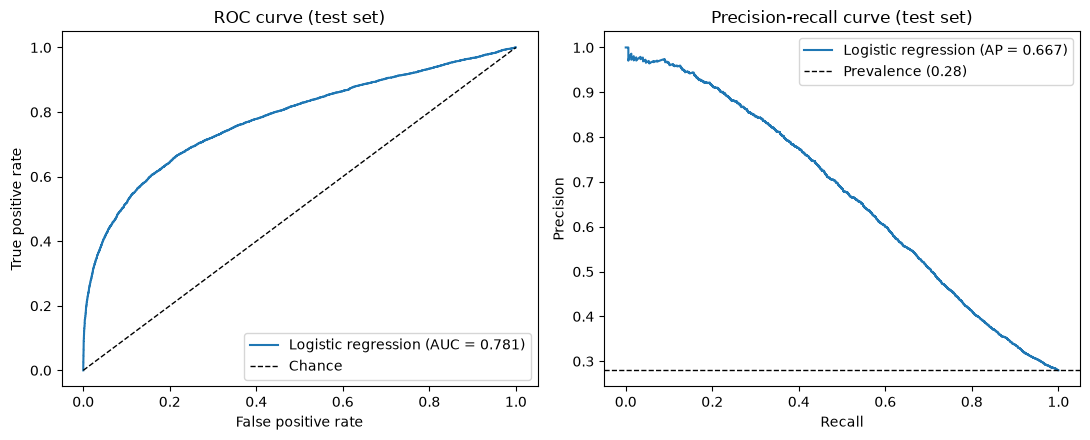

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

fpr, tpr, _ = roc_curve(y_test, tuned_prob)
axes[0].plot(fpr, tpr, label="Logistic regression (AUC = %.3f)" % roc_auc_score(y_test, tuned_prob))
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="Chance")
axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curve (test set)")
axes[0].legend(loc="lower right")

p, r, _ = precision_recall_curve(y_test, tuned_prob)
axes[1].plot(r, p, label="Logistic regression (AP = %.3f)" % average_precision_score(y_test, tuned_prob))
axes[1].axhline(y_test.mean(), color="k", ls="--", lw=1, label="Prevalence (%.2f)" % y_test.mean())
axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision-recall curve (test set)")
axes[1].legend(loc="upper right")

plt.tight_layout()
plt.savefig("figures/lr_roc_pr.png", dpi=200, bbox_inches="tight")
plt.show()

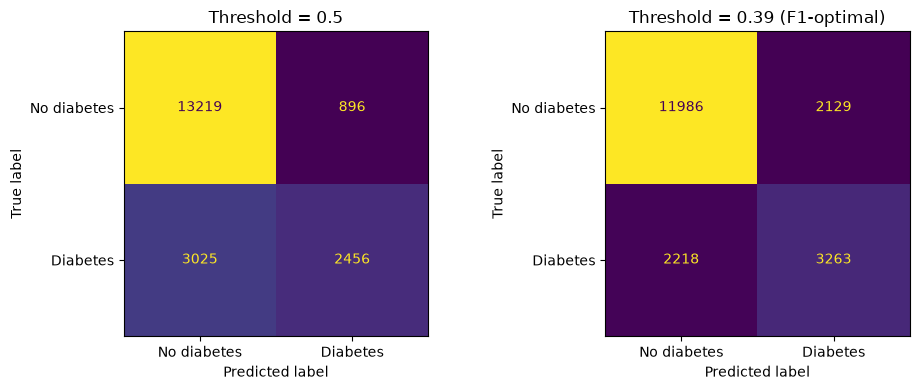

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, thr_, title in zip(axes, [0.5, best_thr], ["Threshold = 0.5", "Threshold = %.2f (F1-optimal)" % best_thr]):
    cm = confusion_matrix(y_test, (tuned_prob >= thr_).astype(int))
    ConfusionMatrixDisplay(cm, display_labels=["No diabetes", "Diabetes"]).plot(ax=ax, colorbar=False, values_format="d")
    ax.set_title(title)
plt.tight_layout()
plt.savefig("figures/lr_confusion_matrices.png", dpi=200, bbox_inches="tight")
plt.show()

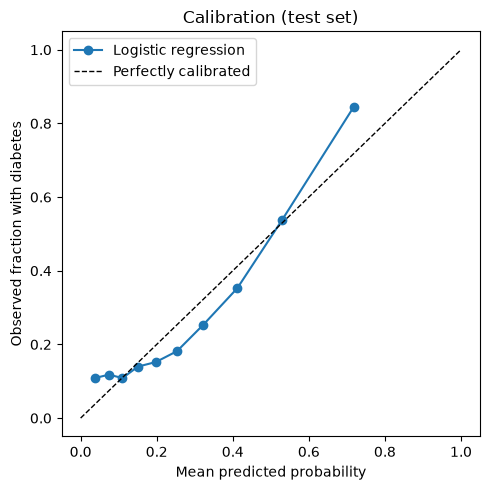

In [8]:
frac_pos, mean_pred = calibration_curve(y_test, tuned_prob, n_bins=10, strategy="quantile")

fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(mean_pred, frac_pos, "o-", label="Logistic regression")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Perfectly calibrated")
ax.set(xlabel="Mean predicted probability", ylabel="Observed fraction with diabetes", title="Calibration (test set)")
ax.legend()
plt.tight_layout()
plt.savefig("figures/lr_calibration.png", dpi=200, bbox_inches="tight")
plt.show()

## Uncertainty in the test AUC

A bootstrap (1,000 resamples of the test set) gives a 95% confidence interval for ROC-AUC. This will be reused to judge whether any AUC difference from gradient boosting is meaningful.

In [9]:
rng = np.random.default_rng(RANDOM_STATE)
y_arr = y_test.to_numpy()
n = len(y_arr)
boot_auc = []
for _ in range(1000):
    idx = rng.integers(0, n, n)
    boot_auc.append(roc_auc_score(y_arr[idx], tuned_prob[idx]))
ci = np.percentile(boot_auc, [2.5, 97.5])
print("Test ROC-AUC: %.4f (95%% bootstrap CI: %.4f to %.4f)" % (roc_auc_score(y_test, tuned_prob), *ci))

Test ROC-AUC: 0.7806 (95% bootstrap CI: 0.7725 to 0.7890)


## Interpretation: odds ratios (statsmodels)

scikit-learn does not report standard errors or p-values, so the same model is refit with `statsmodels` (unpenalized) on the training set. Two versions are shown:

- **Per 1 SD** (standardized predictors): effect sizes are comparable across variables, so this is the one to plot.
- **Per 1 unit** (original scale, median-imputed with the saved imputer): easier to state in the paper, for example "each additional BMI point multiplies the odds by X".

With about 78k training rows, even tiny effects will have very small p-values, so lean on the effect size and confidence interval rather than significance alone.

In [10]:
def odds_ratio_table(result):
    ci_ = result.conf_int()
    out = pd.DataFrame({
        "odds_ratio": np.exp(result.params),
        "ci_low": np.exp(ci_[0]),
        "ci_high": np.exp(ci_[1]),
        "p_value": result.pvalues,
    })
    return out.drop(index="const")

# Per 1 SD (standardized predictors)
sm_scaled = sm.Logit(y_train, sm.add_constant(X_train)).fit(disp=0)
or_scaled = odds_ratio_table(sm_scaled).sort_values("odds_ratio", ascending=False)

# Per 1 unit (original scale)
imputer = joblib.load("data/imputer.joblib")
X_train_raw = pd.read_parquet("data/X_train.parquet")
X_train_raw_imp = pd.DataFrame(imputer.transform(X_train_raw), columns=X_train_raw.columns, index=X_train_raw.index)
sm_raw = sm.Logit(y_train, sm.add_constant(X_train_raw_imp)).fit(disp=0)
or_raw = odds_ratio_table(sm_raw).loc[or_scaled.index]

print("Pseudo R-squared (McFadden): %.4f" % sm_scaled.prsquared)
display_tbl = pd.concat({"Per 1 SD": or_scaled, "Per 1 unit": or_raw}, axis=1)
display_tbl.round(3)

Pseudo R-squared (McFadden): 0.1887


Per 1 SD                        Per 1 unit         \
                          odds_ratio ci_low ci_high p_value odds_ratio ci_low   
bmi                            2.050  2.007   2.094   0.000      1.130  1.126   
age                            1.624  1.589   1.660   0.000      1.034  1.032   
family_history_diabetes        1.485  1.460   1.512   0.000      2.231  2.152   
systolic_bp                    1.290  1.261   1.319   0.000      1.018  1.017   
cigarettes_per_day             1.128  1.109   1.147   0.000      1.021  1.018   
sedentary_hours_per_day        1.075  1.056   1.095   0.000      1.046  1.035   
alcohol_units_per_week         1.025  1.007   1.043   0.006      1.004  1.001   
stress_level                   1.001  0.984   1.019   0.885      1.001  0.982   
added_sugar_grams_per_day      0.988  0.970   1.006   0.174      0.999  0.999   
fiber_grams_per_day            0.928  0.911   0.944   0.000      0.991  0.989   
sleep_hours                    0.914  0.898   0.930   0.000      0.926  0.912   
exercise_minutes_per_week      0.907  0.890   0.924   0.000      0.998  0.998   

                                           
                          ci_high p_value  
bmi                         1.134   0.000  
age                         1.035   0.000  
family_history_diabetes     2.312   0.000  
systolic_bp                 1.020   0.000  
cigarettes_per_day          1.024   0.000  
sedentary_hours_per_day     1.058   0.000  
alcohol_units_per_week      1.007   0.006  
stress_level                1.021   0.885  
added_sugar_grams_per_day   1.000   0.174  
fiber_grams_per_day         0.993   0.000  
sleep_hours                 0.940   0.000  
exercise_minutes_per_week   0.999   0.000

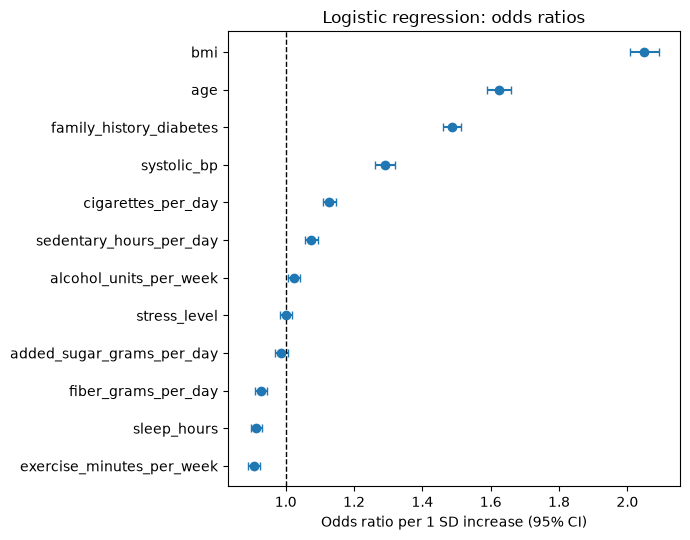

In [11]:
plot_df = or_scaled.sort_values("odds_ratio")
fig, ax = plt.subplots(figsize=(7, 5.5))
ypos = np.arange(len(plot_df))
ax.errorbar(
    plot_df["odds_ratio"], ypos,
    xerr=[plot_df["odds_ratio"] - plot_df["ci_low"], plot_df["ci_high"] - plot_df["odds_ratio"]],
    fmt="o", capsize=3,
)
ax.axvline(1, color="k", ls="--", lw=1)
ax.set_yticks(ypos)
ax.set_yticklabels(plot_df.index)
ax.set_xlabel("Odds ratio per 1 SD increase (95% CI)")
ax.set_title("Logistic regression: odds ratios")
plt.tight_layout()
plt.savefig("figures/lr_odds_ratios.png", dpi=200, bbox_inches="tight")
plt.show()

A note on `family_history_diabetes`: it is binary, so "per 1 SD" is awkward for it. Use the per-1-unit table for that variable, where the odds ratio is simply Yes versus No.

## Save outputs for the model comparison

Test-set predicted probabilities and the headline metrics are saved so the gradient boosting notebook (or a final comparison notebook) can overlay ROC curves and build a metrics table without refitting.

In [12]:
pd.DataFrame({"y_true": y_test.to_numpy(), "prob": tuned_prob}, index=y_test.index).to_parquet("data/lr_test_probs.parquet")
results.to_csv("data/lr_metrics.csv", index=False)
or_scaled.join(or_raw, lsuffix="_per_sd", rsuffix="_per_unit").to_csv("data/lr_odds_ratios.csv")
joblib.dump(best, "data/lr_best_model.joblib")
print(sorted(f for f in os.listdir("data") if f.startswith("lr_")))

['lr_best_model.joblib', 'lr_metrics.csv', 'lr_odds_ratios.csv', 'lr_test_probs.parquet']
